# Exploratory Data Analysis of Solar PV Production

## 1. Introduction

Solar photovoltaic (PV) systems convert solar energy into electricity. Understanding their electricity production patterns is important for renewable energy planning, system performance assessment, and energy forecasting.

This project investigates historical solar electricity production data from photovoltaic installations operated by the City of Calgary, Canada.

The analysis will use Python to inspect, clean, preprocess, and visualize the dataset. Particular attention will be given to temporal production patterns, differences between installations, data quality, and the potential use of historical production data for energy forecasting.

### Project objectives

- Understand the structure and characteristics of the dataset.
- Identify and address data quality issues.
- Analyze temporal patterns in solar electricity production.
- Compare production across photovoltaic installations where appropriate.
- Identify insights relevant to renewable energy assessment and forecasting.

### Dataset

- **Dataset name:** Solar Production (Photovoltaic Output Data)
- **File:** Solar_Energy_Production.csv
- **Main variable of interest:** Energy production (kWh)

### Research question

How does photovoltaic electricity production vary over time and across installations, and what can historical production data reveal about generation patterns and forecasting potential?

In [1]:
# Import the libraries required for data analysis and visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure the default visualization style
sns.set_theme(style="whitegrid")

# Display plots directly inside the notebook
%matplotlib inline

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Data Loading and Inspection

The dataset is stored in CSV format. The pandas library will be used to import the file into a DataFrame, which allows the data to be examined and processed.

The initial inspection will verify that the file has been loaded correctly before assessing its structure, variable types, and statistical characteristics.

In [2]:
# Load the solar production dataset

from pathlib import Path

file_path = Path("../data/Solar_Energy_Production.csv")

df = pd.read_csv(file_path)

# Confirm that the dataset was loaded
print("Dataset loaded successfully.")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")

# Display the first five records
display(df.head())

Dataset loaded successfully.
Number of rows: 258,423
Number of columns: 8


,name,id,address,date,kWh,public_url,installationDate,uid
0,Calgary Fire Hall Headquarters,314106,1212 42 AV SE,2017/09/11 08:00:00 AM,1.130,https://monitoring.solaredge.com/solaredge-web...,2016/11/07,3141062017-09-11 08:00:00
1,Calgary Fire Hall Headquarters,314106,1212 42 AV SE,2017/09/11 09:00:00 AM,2.340,https://monitoring.solaredge.com/solaredge-web...,2016/11/07,3141062017-09-11 09:00:00
2,Calgary Fire Hall Headquarters,314106,1212 42 AV SE,2017/09/11 10:00:00 AM,3.656,https://monitoring.solaredge.com/solaredge-web...,2016/11/07,3141062017-09-11 10:00:00
3,Calgary Fire Hall Headquarters,314106,1212 42 AV SE,2017/09/11 11:00:00 AM,4.577,https://monitoring.solaredge.com/solaredge-web...,2016/11/07,3141062017-09-11 11:00:00
4,Calgary Fire Hall Headquarters,314106,1212 42 AV SE,2017/09/11 12:00:00 PM,6.506,https://monitoring.solaredge.com/solaredge-web...,2016/11/07,3141062017-09-11 12:00:00


### 2.1 Initial Dataset Inspection

The dataset will be examined using its dimensions, column names, data types, and descriptive statistics. This step helps identify the variables available for analysis and highlights potential issues that may require preprocessing.

In [3]:
# Inspect column names, data types, and non-null counts
df.info()

# Generate descriptive statistics
display(df.describe(include="all"))

# Check for missing values in each column
display(df.isnull().sum())

# Check for exact duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 258423 entries, 0 to 258422
Data columns (total 8 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   name              258423 non-null  object 
 1   id                258423 non-null  int64  
 2   address           258423 non-null  object 
 3   date              258423 non-null  object 
 4   kWh               258423 non-null  float64
 5   public_url        258423 non-null  object 
 6   installationDate  258423 non-null  object 
 7   uid               258423 non-null  object 
dtypes: float64(1), int64(1), object(6)
memory usage: 15.8+ MB


,name,id,address,date,kWh,public_url,installationDate,uid
count,258423,258423.000000,258423,258423,258423.000000,258423,258423,258423
unique,11,NaN,11,36192,NaN,22,11,258423
top,Southland Leisure Centre,NaN,2000 SOUTHLAND DR SW,2017/12/05 04:00:00 PM,NaN,https://monitoringpublic.solaredge.com/solared...,2015/09/01,3141062017-09-11 08:00:00
freq,31590,NaN,31590,11,NaN,24533,31590,1
mean,NaN,372581.033132,NaN,NaN,38.059762,NaN,NaN,NaN
std,NaN,130344.544572,NaN,NaN,71.598031,NaN,NaN,NaN
min,NaN,164440.000000,NaN,NaN,0.000000,NaN,NaN,NaN
25%,NaN,314106.000000,NaN,NaN,1.370000,NaN,NaN,NaN
50%,NaN,331901.000000,NaN,NaN,8.034000,NaN,NaN,NaN
75%,NaN,551172.000000,NaN,NaN,35.876000,NaN,NaN,NaN


name                0
id                  0
address             0
date                0
kWh                 0
public_url          0
installationDate    0
uid                 0
dtype: int64

Number of duplicate rows: 0


### 2.2 Data Quality Assessment

The initial inspection indicates that the dataset contains no
missing values in the displayed columns and no exact duplicate
rows. However, further checks are required to assess timestamp
validity, chronological consistency, and gaps in the recorded
production data.

The next step is to convert the date columns to appropriate
datetime formats and examine the range and distribution of
the recorded energy production values.

In [4]:

# Inspect the date columns and energy production values

print("Column names:")
print(df.columns.tolist())

# Convert date columns to datetime format
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["installationDate"] = pd.to_datetime(
    df["installationDate"], errors="coerce"
)

# Check whether any dates failed to parse
print("\nInvalid or missing production dates:", df["date"].isna().sum())
print("Invalid or missing installation dates:",
      df["installationDate"].isna().sum())

# Examine the date range
print("\nProduction date range:")
print("Earliest:", df["date"].min())
print("Latest:", df["date"].max())

# Examine the energy production variable
print("\nEnergy production summary:")
display(df["kWh"].describe())

print("\nNegative energy readings:", (df["kWh"] < 0).sum())
print("Zero energy readings:", (df["kWh"] == 0).sum())


Column names:
['name', 'id', 'address', 'date', 'kWh', 'public_url', 'installationDate', 'uid']

Invalid or missing production dates: 0
Invalid or missing installation dates: 0

Production date range:
Earliest: 2015-09-01 14:30:00
Latest: 2023-03-16 19:00:00

Energy production summary:


count    258423.000000
mean         38.059762
std          71.598031
min           0.000000
25%           1.370000
50%           8.034000
75%          35.876000
max         514.462000
Name: kWh, dtype: float64


Negative energy readings: 0
Zero energy readings: 1176


### 2.3 Interpretation of Initial Data Quality Results

The dataset contains 258,423 observations, with production
timestamps ranging from September 1, 2015, to March 16, 2023.

The datetime conversion was successful, with no invalid or
missing values detected in the production and installation
date columns.

The energy production variable has a mean of approximately
38.06 kWh and a median of 8.034 kWh. The substantial
difference between these values suggests a positively
skewed distribution.

The minimum recorded production is 0 kWh, while the maximum
is approximately 514.46 kWh. No negative production values
were identified.

A total of 1,176 zero-production observations were detected.
These values will be retained during the initial analysis,
as they may represent legitimate operating conditions.

Further investigation is required to identify potential
temporal gaps, inconsistent records, and production outliers.

## 3. Data Cleaning and Preprocessing

### 3.1 Installation-Level Data Assessment

The dataset contains electricity production measurements
from multiple photovoltaic installations.

Before performing temporal resampling and outlier detection,
the number of observations, recording periods, and production
characteristics of each installation will be examined.

This assessment will help identify differences in data
coverage and system behavior.

In [5]:

# Examine the number of PV installations
print("Number of unique installations:", df["id"].nunique())

# Summarize observations and energy production by installation
installation_summary = (
    df.groupby(["id", "name"])
    .agg(
        observations=("kWh", "size"),
        first_record=("date", "min"),
        last_record=("date", "max"),
        mean_energy_kWh=("kWh", "mean"),
        max_energy_kWh=("kWh", "max"),
        total_energy_kWh=("kWh", "sum")
    )
    .reset_index()
)

# Display the installation-level summary
display(installation_summary.round(2))

# Check repeated timestamps within the same installation
duplicate_timestamps = df.duplicated(
    subset=["id", "date"]
).sum()

print("Duplicate installation-timestamp records:",
      duplicate_timestamps)


Number of unique installations: 11


,id,name,observations,first_record,last_record,mean_energy_kWh,max_energy_kWh,total_energy_kWh
0,164440,Southland Leisure Centre,31590,2015-09-01 14:30:00,2023-03-16 18:00:00,36.32,123.62,1147493.63
1,308057,Hillhurst Sunnyside Community Association,23467,2016-10-03 13:00:00,2023-03-15 19:00:00,7.94,29.00,186441.26
2,314106,Calgary Fire Hall Headquarters,25637,2016-11-24 14:00:00,2023-03-16 19:00:00,4.30,16.60,110211.61
3,319086,Whitehorn Multi-Service Centre,27716,2017-02-13 09:45:00,2023-03-16 19:00:00,92.32,369.06,2558802.50
4,331901,City of Calgary North Corporate Warehouse,27092,2016-12-23 09:30:00,2023-03-16 19:00:00,28.38,102.86,768964.64
5,332785,Richmond - Knob Hill Community Hall,26623,2016-12-09 11:00:00,2023-03-16 19:00:00,2.82,9.28,75130.28
6,355827,Glenmore Water Treatment Plant,25920,2017-03-08 10:00:00,2023-03-12 17:00:00,59.84,239.97,1551177.72
7,551172,CFD Firehall #7,22659,2017-09-21 07:00:00,2023-03-16 19:00:00,7.51,29.21,170080.89
8,570079,Manchester Building M,22533,2017-10-05 13:15:00,2023-03-16 19:00:00,8.13,34.12,183243.24
9,577650,Bearspaw Water Treatment Plant,24869,2017-11-21 10:45:00,2023-03-16 19:00:00,123.96,514.46,3082637.60


Duplicate installation-timestamp records: 0


### 3.2 Interpretation of Installation-Level Assessment

The dataset contains 11 photovoltaic installations with
different observation counts, recording periods, and
electricity production characteristics.

Bearspaw Water Treatment Plant recorded the highest
average electricity production among the installations,
at approximately 123.96 kWh per observation, with a
maximum recorded value of 514.46 kWh.

Whitehorn Multi-Service Centre also exhibited relatively
high production, with an average of approximately
92.32 kWh per observation.

In contrast, Richmond–Knob Hill Community Hall recorded
a much lower average production of approximately
2.82 kWh per observation.

The Telus Spark installation contains only 317
observations, indicating substantially shorter data
coverage than most other installations.

No duplicate installation-timestamp combinations
were detected.

These findings demonstrate that production
characteristics and recording coverage vary
considerably across installations.

Consequently, installation-level differences should
be considered during preprocessing, outlier detection,
and comparative analysis.

### 3.3 Temporal Consistency and Missing Interval Assessment

Although the dataset contains no missing datetime values,
some expected recording intervals may be absent.

This section examines the time differences between
consecutive observations for each PV installation.

The objective is to identify recording frequencies,
potential temporal gaps, and inconsistencies that may
affect time-series analysis and forecasting.

In [6]:

# Sort observations chronologically within each installation
df = df.sort_values(["id", "date"]).copy()

# Calculate time differences between consecutive observations
df["time_difference"] = (
    df.groupby("id")["date"].diff()
)

# Summarize the most common recording intervals
print("Most common recording intervals:")
display(df["time_difference"].value_counts().head(15))

# Count intervals longer than one hour
long_gaps = df["time_difference"] > pd.Timedelta(hours=1)

print("\nNumber of intervals longer than one hour:",
      long_gaps.sum())

# Summarize temporal gaps by installation
gap_summary = (
    df.assign(
        gap_over_1h=long_gaps,
        gap_over_24h=(
            df["time_difference"] > pd.Timedelta(hours=24)
        )
    )
    .groupby(["id", "name"])
    .agg(
        observations=("date", "size"),
        gaps_over_1h=("gap_over_1h", "sum"),
        gaps_over_24h=("gap_over_24h", "sum"),
        median_interval=("time_difference", "median")
    )
    .reset_index()
)

display(gap_summary)


Most common recording intervals:


time_difference
0 days 01:00:00    236611
0 days 08:00:00      2719
0 days 16:00:00      2698
0 days 10:00:00      2657
0 days 12:00:00      2202
0 days 09:00:00      1909
0 days 14:00:00      1714
0 days 15:00:00      1449
0 days 11:00:00      1325
0 days 13:00:00      1277
0 days 17:00:00      1027
0 days 18:00:00       646
0 days 00:15:00       349
0 days 00:45:00       337
0 days 19:00:00       303
Name: count, dtype: int64


Number of intervals longer than one hour: 21089


,id,name,observations,gaps_over_1h,gaps_over_24h,median_interval
0,164440,Southland Leisure Centre,31590,2586,43,0 days 01:00:00
1,308057,Hillhurst Sunnyside Community Association,23467,2016,87,0 days 01:00:00
2,314106,Calgary Fire Hall Headquarters,25637,2133,28,0 days 01:00:00
3,319086,Whitehorn Multi-Service Centre,27716,2201,8,0 days 01:00:00
4,331901,City of Calgary North Corporate Warehouse,27092,2211,16,0 days 01:00:00
5,332785,Richmond - Knob Hill Community Hall,26623,2205,36,0 days 01:00:00
6,355827,Glenmore Water Treatment Plant,25920,2067,36,0 days 01:00:00
7,551172,CFD Firehall #7,22659,1882,20,0 days 01:00:00
8,570079,Manchester Building M,22533,1877,21,0 days 01:00:00
9,577650,Bearspaw Water Treatment Plant,24869,1873,6,0 days 01:00:00


### 3.4 Interpretation of Temporal Consistency

The temporal consistency assessment indicates that
the dataset predominantly follows an hourly recording
frequency.

A total of 236,611 consecutive observations were
separated by exactly one hour, representing approximately
91.6% of the within-installation intervals.

However, 21,089 intervals exceeded one hour, indicating
discontinuities in the recorded time series.

Several common gaps ranged between 8 and 16 hours.
These intervals may correspond to overnight periods
when photovoltaic electricity generation is limited
or absent.

All 11 installations exhibited a median recording
interval of one hour.

Hillhurst Sunnyside Community Association recorded
87 intervals exceeding 24 hours, the highest among
the installations examined.

These findings suggest that the dataset has a
predominantly hourly structure but is not a fully
continuous hourly time series.

Consequently, temporal resampling should be performed
carefully to avoid treating unrecorded observations
as confirmed zero electricity production.

### 3.5 Distribution of Recording Hours

This section examines the distribution of observations
across the 24 hours of the day.

The objective is to identify whether recorded production
measurements are concentrated during daylight hours
and to assess how the recording schedule may influence
the interpretation of temporal gaps.

,Number of observations
hour,
0,125
1,125
2,114
3,110
4,107
5,3007
6,7486
7,12199
8,17916


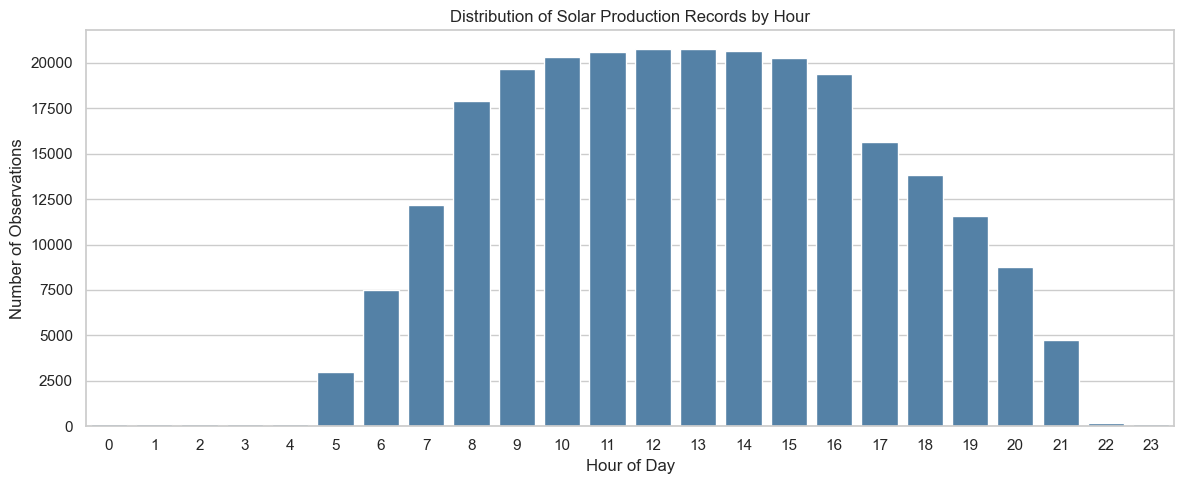

In [7]:

# Extract the hour from each production timestamp
df["hour"] = df["date"].dt.hour

# Count observations for each hour
hourly_counts = (
    df["hour"]
    .value_counts()
    .reindex(range(24), fill_value=0)
    .sort_index()
)

# Display the hourly observation counts
display(
    hourly_counts.rename("Number of observations").to_frame()
)

# Plot the distribution of observations by hour
plt.figure(figsize=(12, 5))

sns.barplot(
    x=hourly_counts.index,
    y=hourly_counts.values,
    color="steelblue"
)

plt.title("Distribution of Solar Production Records by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Observations")
plt.xticks(range(24))
plt.tight_layout()
plt.show()


### 3.6 Interpretation of Recording Hour Distribution

The distribution of recorded observations shows a
strong concentration during daylight hours.

Very few or no observations are available during
the early morning hours between midnight and 04:00.

The number of records increases from approximately
05:00 and reaches its highest concentration
between 10:00 and 15:00.

After approximately 16:00, the number of recorded
observations gradually decreases, with very few
records remaining after 21:00.

This pattern is consistent with the operating
characteristics of photovoltaic systems.

The results also provide a possible explanation
for the frequent overnight gaps identified during
the temporal consistency assessment.

However, this visualization represents observation
frequency rather than electricity generation.

Additional analysis of hourly energy production
is required to identify actual production peaks.

Unrecorded nighttime intervals will not
automatically be replaced with zero values.

### 3.7 Feature Engineering

Feature engineering involves creating new variables from
existing data to support analysis and visualization.

In this study, temporal features will be extracted from
the production timestamps, including the hour, day,
month, year, and season.

These features will help investigate daily and seasonal
variations in photovoltaic electricity generation.

In [8]:

# Create time-based features from production timestamps

df["hour"] = df["date"].dt.hour
df["day"] = df["date"].dt.day
df["month"] = df["date"].dt.month
df["year"] = df["date"].dt.year
df["day_of_week"] = df["date"].dt.dayofweek

# Assign meteorological seasons for Calgary
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Autumn"

df["season"] = df["month"].apply(get_season)

# Inspect the newly created features
display(
    df[[
        "date", "hour", "day", "month",
        "year", "day_of_week", "season", "kWh"
    ]].head(10)
)

# Confirm the new DataFrame dimensions
print("Updated dataset shape:", df.shape)


,date,hour,day,month,year,day_of_week,season,kWh
23003,2015-09-01 14:30:00,14,1,9,2015,1,Autumn,27.805
23005,2015-09-01 15:30:00,15,1,9,2015,1,Autumn,30.559
23006,2015-09-01 16:30:00,16,1,9,2015,1,Autumn,23.613
23007,2015-09-01 17:30:00,17,1,9,2015,1,Autumn,15.257
23008,2015-09-01 18:30:00,18,1,9,2015,1,Autumn,7.896
23009,2015-09-01 19:30:00,19,1,9,2015,1,Autumn,1.885
23010,2015-09-01 20:30:00,20,1,9,2015,1,Autumn,41.066
23011,2015-09-01 21:30:00,21,1,9,2015,1,Autumn,57.844
23012,2015-09-01 22:30:00,22,1,9,2015,1,Autumn,48.606
23013,2015-09-01 23:30:00,23,1,9,2015,1,Autumn,31.482


Updated dataset shape: (258423, 15)


### 3.8 Timestamp Validation and Outlier Assessment

The initial temporal analysis revealed that some
photovoltaic installations recorded positive electricity
production during late-evening hours.

These observations require further investigation because
photovoltaic electricity generation generally depends
on the availability of solar radiation.

Potential explanations include timezone differences,
timestamp conventions, data aggregation methods,
or measurement anomalies.

This section examines production values across recording
hours and identifies potentially unusual values within
individual installations.

No observations will be removed or modified during this
assessment. Cleaning decisions will be based on the
results of the investigation.

In [9]:

# Investigate production readings recorded late in the evening

late_evening = df[df["hour"] >= 21].copy()

print("Number of late-evening observations:", len(late_evening))

print("\nLate-evening energy production summary:")
display(late_evening["kWh"].describe())

# Summarize late-evening readings by installation
late_evening_summary = (
    late_evening.groupby(["id", "name"])
    .agg(
        observations=("kWh", "size"),
        mean_kWh=("kWh", "mean"),
        max_kWh=("kWh", "max")
    )
    .reset_index()
)

display(late_evening_summary.round(2))

# Examine the distribution of observations by year
print("\nLate-evening observations by year:")
display(late_evening["year"].value_counts().sort_index())


Number of late-evening observations: 5026

Late-evening energy production summary:


count    5026.000000
mean        0.789056
std         3.337805
min         0.000000
25%         0.039000
50%         0.140000
75%         0.605750
max        66.249000
Name: kWh, dtype: float64

,id,name,observations,mean_kWh,max_kWh
0,164440,Southland Leisure Centre,652,2.27,66.25
1,308057,Hillhurst Sunnyside Community Association,398,0.10,0.92
2,314106,Calgary Fire Hall Headquarters,414,0.05,0.71
3,319086,Whitehorn Multi-Service Centre,525,1.53,21.04
4,331901,City of Calgary North Corporate Warehouse,512,0.42,3.80
5,332785,Richmond - Knob Hill Community Hall,455,0.04,0.38
6,355827,Glenmore Water Treatment Plant,655,0.68,6.95
7,551172,CFD Firehall #7,384,0.13,1.32
8,570079,Manchester Building M,375,0.11,1.01
9,577650,Bearspaw Water Treatment Plant,656,1.30,19.06



Late-evening observations by year:


year
2015     44
2016     86
2017    742
2018    964
2019    749
2020    812
2021    807
2022    822
Name: count, dtype: int64

#### Interpretation of Late-Evening Production Assessment

The analysis identified 5,026 observations recorded at
or after 21:00, representing approximately 1.94% of
the complete dataset.

Late-evening electricity production was generally low,
with a mean of approximately 0.789 kWh and a median
of 0.140 kWh.

However, the maximum recorded value reached
66.249 kWh, indicating that some observations were
substantially higher than typical late-evening readings.

The observations occurred across multiple photovoltaic
installations. Southland Leisure Centre recorded the
highest average late-evening production among the
installations examined, at approximately 2.27 kWh.

Late-evening observations were present across multiple
years between 2015 and 2022, with the highest count
occurring in 2018 (964 observations).

These findings indicate that late-evening readings are
not isolated to a single installation or year.

Possible explanations include timezone conventions,
measurement intervals, and seasonal daylight variations.

However, the dataset's timestamp conventions have not
yet been verified against the original documentation.

Consequently, these observations cannot be classified
as measurement errors based solely on their recording
hours.

The observations will be retained pending further
investigation.

### 3.9 Hourly Electricity Production Profile

The average electricity production for each recording
hour is calculated to examine the daily generation profile.

This analysis helps identify peak production periods
and investigate potentially unusual late-evening readings.

Because photovoltaic installations have different
capacities and recording coverage, the results represent
the average recorded production rather than a
capacity-normalized system performance measure.

,mean,median,count
hour,,,
0,1.43,0.27,125
1,0.54,0.23,125
2,0.42,0.16,114
3,0.35,0.23,110
4,0.33,0.22,107
5,0.23,0.06,3007
6,2.13,0.57,7486
7,7.40,1.76,12199
8,16.53,3.16,17916


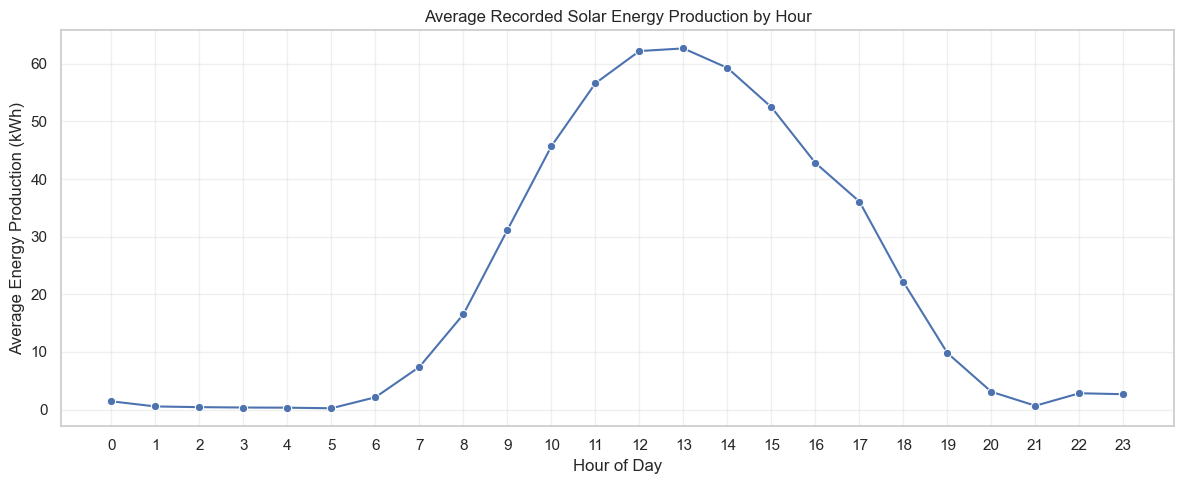

In [10]:

# Calculate average production by hour
hourly_production = (
    df.groupby("hour")["kWh"]
    .agg(["mean", "median", "count"])
    .reindex(range(24))
)

display(hourly_production.round(2))

# Visualize average recorded production
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hourly_production,
    x=hourly_production.index,
    y="mean",
    marker="o"
)

plt.title("Average Recorded Solar Energy Production by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Energy Production (kWh)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


#### Interpretation of Hourly Electricity Production Profile

The hourly electricity production analysis reveals
a distinct daily generation pattern consistent with
the expected behavior of photovoltaic systems.

Average recorded production increases during the
morning, reaching its highest value of approximately
62.67 kWh at 13:00.

Production remains relatively high between 12:00
and 14:00 before declining during the afternoon
and evening.

This pattern is consistent with the influence of
solar irradiance on photovoltaic electricity generation.

The results also reveal substantial differences
between mean and median production values.

At 13:00, the mean is approximately 62.67 kWh,
while the median is 18.65 kWh.

This suggests a positively skewed distribution,
potentially reflecting differences in installation
sizes and production capacities.

Small positive production values are also observed
during late-night and early-morning hours.

These observations may be associated with timestamp
conventions, measurement intervals, or data anomalies
and require further investigation.

The analysis represents average recorded energy per
observation rather than capacity-normalized production.

Overall, the hourly production profile demonstrates
a strong diurnal pattern, with maximum average
recorded generation occurring around midday.

### 3.10 Installation-Specific Outlier Detection

The interquartile range (IQR) method is used to identify
potentially unusual energy production values.

Outlier thresholds are calculated separately for each
photovoltaic installation to account for differences
in production magnitude.

Observations outside the calculated thresholds will be
flagged for investigation rather than automatically removed.

The IQR method is an exploratory screening technique,
not definitive evidence of measurement error.

In [11]:

# Calculate installation-specific IQR thresholds

q1 = df.groupby("id")["kWh"].transform(
    lambda x: x.quantile(0.25)
)

q3 = df.groupby("id")["kWh"].transform(
    lambda x: x.quantile(0.75)
)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Flag potential outliers without removing them
df["potential_outlier"] = (
    (df["kWh"] < lower_bound) |
    (df["kWh"] > upper_bound)
)

# Summarize potential outliers by installation
outlier_summary = (
    df.groupby(["id", "name"])
    .agg(
        observations=("kWh", "size"),
        potential_outliers=("potential_outlier", "sum")
    )
    .reset_index()
)

outlier_summary["outlier_percentage"] = (
    outlier_summary["potential_outliers"]
    / outlier_summary["observations"] * 100
)

display(outlier_summary.round(2))

print(
    "Total potential outliers:",
    df["potential_outlier"].sum()
)


,id,name,observations,potential_outliers,outlier_percentage
0,164440,Southland Leisure Centre,31590,0,0.00
1,308057,Hillhurst Sunnyside Community Association,23467,0,0.00
2,314106,Calgary Fire Hall Headquarters,25637,0,0.00
3,319086,Whitehorn Multi-Service Centre,27716,0,0.00
4,331901,City of Calgary North Corporate Warehouse,27092,0,0.00
5,332785,Richmond - Knob Hill Community Hall,26623,0,0.00
6,355827,Glenmore Water Treatment Plant,25920,0,0.00
7,551172,CFD Firehall #7,22659,0,0.00
8,570079,Manchester Building M,22533,11,0.05
9,577650,Bearspaw Water Treatment Plant,24869,0,0.00


Total potential outliers: 25


#### Interpretation of Installation-Specific Outlier Detection

The installation-specific interquartile range (IQR)
method identified 25 potential outliers among
258,423 observations, representing approximately
0.0097% of the dataset.

Potential outliers were detected in only two of
the eleven photovoltaic installations.

Manchester Building M contained 11 flagged
observations out of 22,533 records, representing
approximately 0.05% of its observations.

Telus Spark contained 14 flagged observations
out of 317 records, representing approximately
4.42% of its observations.

The remaining nine installations contained no
observations outside their respective IQR thresholds.

The higher percentage of flagged observations at
Telus Spark may be influenced by its relatively
small sample size and limited recording period.

Although relatively few observations exceed the
calculated thresholds, statistical outliers do not
necessarily represent measurement errors.

Photovoltaic electricity generation is influenced
by solar irradiance, weather conditions, seasonal
variation, and installation characteristics.

Consequently, all 25 flagged observations will be
retained pending further investigation.

The original energy production values will remain
unchanged during this assessment.

### 3.11 Examination of Flagged Outlier Observations

The observations identified by the installation-specific
IQR method are examined individually to assess their
timestamps, production values, and installation origins.

This assessment supports informed decisions regarding
data retention and potential cleaning.

In [12]:

# Examine all flagged observations

flagged_observations = (
    df.loc[
        df["potential_outlier"],
        ["id", "name", "date", "kWh",
         "hour", "month", "season"]
    ]
    .sort_values(["id", "date"])
)

print("Number of flagged observations:",
      len(flagged_observations))

display(flagged_observations)

# Compare flagged readings with installation statistics
installation_stats = (
    df.groupby(["id", "name"])["kWh"]
    .agg(["min", "median", "mean", "max"])
    .round(2)
)

display(
    installation_stats.loc[
        installation_stats.index.get_level_values("id").isin(
            flagged_observations["id"].unique()
        )
    ]
)


Number of flagged observations: 25


,id,name,date,kWh,hour,month,season
47921,570079,Manchester Building M,2018-07-14 13:00:00,33.312,13,7,Summer
95101,570079,Manchester Building M,2019-05-02 13:00:00,33.288,13,5,Spring
157932,570079,Manchester Building M,2020-04-06 13:00:00,33.748,13,4,Spring
155624,570079,Manchester Building M,2020-04-13 13:00:00,33.685,13,4,Spring
144773,570079,Manchester Building M,2020-04-26 13:00:00,33.508,13,4,Spring
128412,570079,Manchester Building M,2020-05-14 12:00:00,33.225,12,5,Spring
128417,570079,Manchester Building M,2020-05-14 13:00:00,34.120,13,5,Spring
164938,570079,Manchester Building M,2020-06-16 13:00:00,33.979,13,6,Summer
157374,570079,Manchester Building M,2020-07-12 13:00:00,33.349,13,7,Summer
171651,570079,Manchester Building M,2021-06-07 14:00:00,33.732,14,6,Summer


,,min,median,mean,max
id,name,,,,
570079,Manchester Building M,0.0,4.50,8.13,34.12
594148,Telus Spark,0.0,3.54,4.21,23.88


#### Interpretation and Outlier Handling Decision

The examination of the 25 flagged observations
revealed that the potentially unusual readings
were concentrated in two photovoltaic installations:
Manchester Building M and Telus Spark.

For Manchester Building M, the 11 flagged observations
occurred between 12:00 and 14:00 during spring and
summer months. Their recorded energy values ranged
from approximately 33.23 to 34.12 kWh.

These observations may represent periods of relatively
high solar electricity generation.

For Telus Spark, the 14 flagged observations occurred
between 10:00 and 13:00 during November and December
2017. Their recorded values ranged from approximately
13.51 to 23.88 kWh.

The relatively small number of available observations
for this installation may affect the reliability of
its IQR thresholds.

Although these observations exceeded the
installation-specific statistical thresholds,
their occurrence during daytime hours provides
no immediate evidence of invalid measurements.

Therefore, all 25 flagged observations will be
retained for subsequent exploratory analysis.

The potential_outlier indicator will also be
preserved to support future sensitivity analysis.

This decision is provisional because installation
capacity information and original measurement
documentation have not yet been independently verified.

Overall, the outlier assessment demonstrates the
importance of considering temporal patterns and
installation-specific characteristics before
removing statistically unusual photovoltaic
production readings.

In [13]:

# Create a working copy for exploratory analysis

df_clean = df.copy()

# Retain all observations, including flagged outliers
print("Original observations:", len(df))
print("Working observations:", len(df_clean))

print(
    "Retained potential outliers:",
    df_clean["potential_outlier"].sum()
)

print("Working dataset shape:", df_clean.shape)


Original observations: 258423
Working observations: 258423
Retained potential outliers: 25
Working dataset shape: (258423, 16)


# 4. Exploratory Data Analysis (EDA)

This section investigates temporal variations and
installation-specific patterns in solar energy
production.

The analysis focuses on daily, monthly, seasonal,
and annual production trends, as well as differences
across photovoltaic installations.

The objective is to identify meaningful patterns,
understand production variability, and provide
insights into the factors influencing recorded
solar electricity generation.



### 4.1 Daily Solar Energy Production Trends

This subsection examines the daily variation in recorded solar
energy production across the photovoltaic installations.

Daily energy production is aggregated using the available
observations to identify temporal fluctuations and overall
production patterns.

Because recording intervals and data availability vary,
daily totals are interpreted as recorded energy rather than
necessarily complete daily generation.


In [14]:

# 4.1 Daily Solar Energy Production Trends

# Create a working copy for daily analysis
daily_df = df_clean.copy()

# Ensure production timestamps are datetime
daily_df["date"] = pd.to_datetime(daily_df["date"])

# Extract calendar date
daily_df["production_day"] = daily_df["date"].dt.date

# Aggregate recorded energy production by day
daily_production = (
    daily_df.groupby("production_day")["kWh"]
    .agg(["sum", "mean", "count"])
    .reset_index()
)

# Rename columns for clarity
daily_production.columns = [
    "date",
    "total_kWh",
    "mean_kWh",
    "observations"
]

# Convert date back to datetime
daily_production["date"] = pd.to_datetime(
    daily_production["date"]
)

# Display summary
print("Number of days:", len(daily_production))

print("\nDaily production summary:")
display(daily_production.describe())

print("\nFirst 10 daily records:")
display(daily_production.head(10))


Number of days: 2716

Daily production summary:


,date,total_kWh,mean_kWh,observations
count,2716,2716.000000,2716.000000,2716.000000
mean,2019-06-22 13:27:28.895434496,3621.324722,32.606365,95.148380
min,2015-09-01 00:00:00,0.000000,0.000000,1.000000
25%,2017-08-17 18:00:00,553.475500,11.718769,61.000000
50%,2019-06-27 12:00:00,2501.382500,33.295632,102.000000
75%,2021-05-06 06:00:00,6448.932250,51.922115,139.000000
max,2023-03-16 00:00:00,12530.798000,84.814803,171.000000
std,NaN,3356.465164,21.998459,50.964506



First 10 daily records:


,date,total_kWh,mean_kWh,observations
0,2015-09-01,286.013,28.601300,10
1,2015-09-02,681.646,32.459333,21
2,2015-09-03,647.906,30.852667,21
3,2015-09-04,102.448,5.122400,20
4,2015-09-05,93.432,4.917474,19
5,2015-09-06,367.626,18.381300,20
6,2015-09-07,574.996,30.262947,19
7,2015-09-08,489.814,24.490700,20
8,2015-09-09,732.002,36.600100,20
9,2015-09-10,628.674,33.088105,19


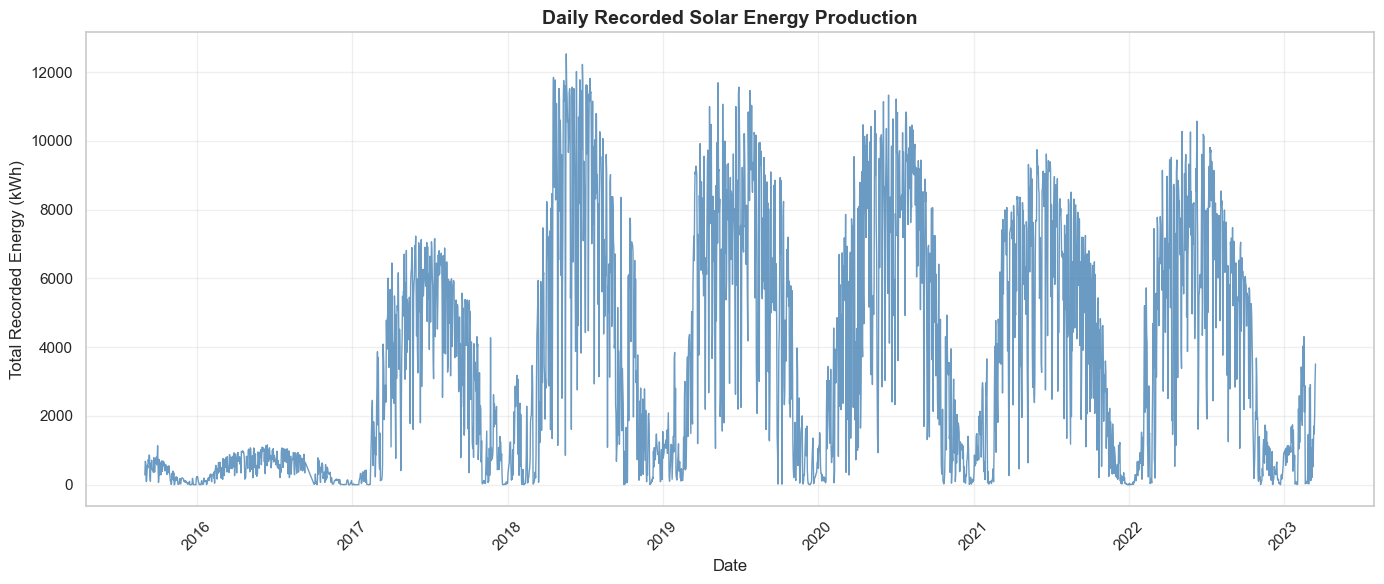

In [15]:

# Visualize daily recorded solar energy production

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.plot(
    daily_production["date"],
    daily_production["total_kWh"],
    color="steelblue",
    linewidth=1,
    alpha=0.8
)

plt.title(
    "Daily Recorded Solar Energy Production",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Total Recorded Energy (kWh)")

plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()


### 4.1.1 Interpretation of Daily Solar Energy Production Trends

The daily solar energy production analysis reveals substantial temporal variability in recorded photovoltaic electricity generation between September 2015 and March 2023.

The dataset contains 2,716 days with recorded observations, with an average daily recorded production of approximately 3,621.32 kWh and a maximum of 12,530.80 kWh.

**Key observations:**

1. **Seasonal variability:** The time-series visualization reveals recurring fluctuations in daily solar energy production. Higher recorded production generally occurs during periods consistent with increased seasonal solar availability, while lower values appear during other parts of the year.

2. **Interannual differences:** Recorded production is relatively low during 2015–2016 compared with subsequent years. These differences may partly reflect changes in the number of active or reporting photovoltaic installations rather than improvements in generation efficiency.

3. **Daily fluctuations:** Considerable variation occurs within individual seasons, potentially reflecting meteorological conditions, installation performance, and differences in data completeness.

4. **Production extremes:** The maximum daily recorded production reaches approximately 12,530.80 kWh, illustrating the considerable variation in aggregate recorded generation.

**Analytical limitation:**

Daily totals represent the sum of available recorded energy observations. Because the number of reporting installations and observations varies across days, these totals should not be interpreted as directly comparable measures of complete daily generation without additional coverage assessment.

**Conclusion:**

The analysis provides preliminary evidence of recurring temporal patterns in solar energy production. Further monthly and seasonal analyses are necessary to characterize these patterns and distinguish potential seasonal effects from differences in installation coverage.


## 4.2 Monthly Solar Energy Production Patterns

This subsection investigates monthly variations in recorded
solar energy production across the photovoltaic installations.

Monthly aggregation is used to examine recurring seasonal
patterns, differences in recorded production, and changes
in data availability.

Both total recorded energy and average energy per observation
are considered to avoid relying solely on aggregate totals
that may be affected by unequal reporting coverage.


In [16]:

# 4.2 Monthly Solar Energy Production Patterns

# Create a working copy
monthly_df = df_clean.copy()

# Ensure timestamps are datetime
monthly_df["date"] = pd.to_datetime(monthly_df["date"])

# Create monthly period
monthly_df["year_month"] = monthly_df["date"].dt.to_period("M")

# Aggregate production by calendar month
monthly_production = (
    monthly_df.groupby("year_month")["kWh"]
    .agg(["sum", "mean", "median", "count"])
    .reset_index()
)

# Rename columns
monthly_production.columns = [
    "year_month",
    "total_kWh",
    "mean_kWh",
    "median_kWh",
    "observations"
]

# Convert monthly period to timestamp for plotting
monthly_production["month_date"] = (
    monthly_production["year_month"].dt.to_timestamp()
)

print("Number of months with observations:",
      len(monthly_production))

print("\nMonthly production summary:")
display(monthly_production[
    ["total_kWh", "mean_kWh", "median_kWh", "observations"]
].describe().round(2))

print("\nFirst 10 monthly records:")
display(monthly_production.head(10))


Number of months with observations: 91

Monthly production summary:


,total_kWh,mean_kWh,median_kWh,observations
count,91.00,91.00,91.00,91.00
mean,108082.61,33.29,10.75,2839.81
std,89191.10,16.55,10.05,1539.82
min,1206.77,2.29,0.30,158.00
25%,22809.32,17.13,3.24,1933.50
50%,91759.39,39.98,10.10,2875.00
75%,186940.50,46.57,12.89,4139.00
max,283675.71,60.71,46.23,5063.00



First 10 monthly records:


,year_month,total_kWh,mean_kWh,median_kWh,observations,month_date
0,2015-09,15475.746,35.172150,27.3125,440,2015-09-01
1,2015-10,15068.149,41.510052,33.4330,363,2015-10-01
2,2015-11,4302.924,15.819574,8.5155,272,2015-11-01
3,2015-12,1722.964,7.939926,3.4200,217,2015-12-01
4,2016-01,3081.863,11.288875,4.2730,273,2016-01-01
5,2016-02,9544.109,32.910721,19.4835,290,2016-02-01
6,2016-03,18105.476,46.905378,38.7410,386,2016-03-01
7,2016-04,21241.109,48.942647,38.3265,434,2016-04-01
8,2016-05,22154.348,47.136911,40.2335,470,2016-05-01
9,2016-06,25612.561,50.319373,46.2340,509,2016-06-01


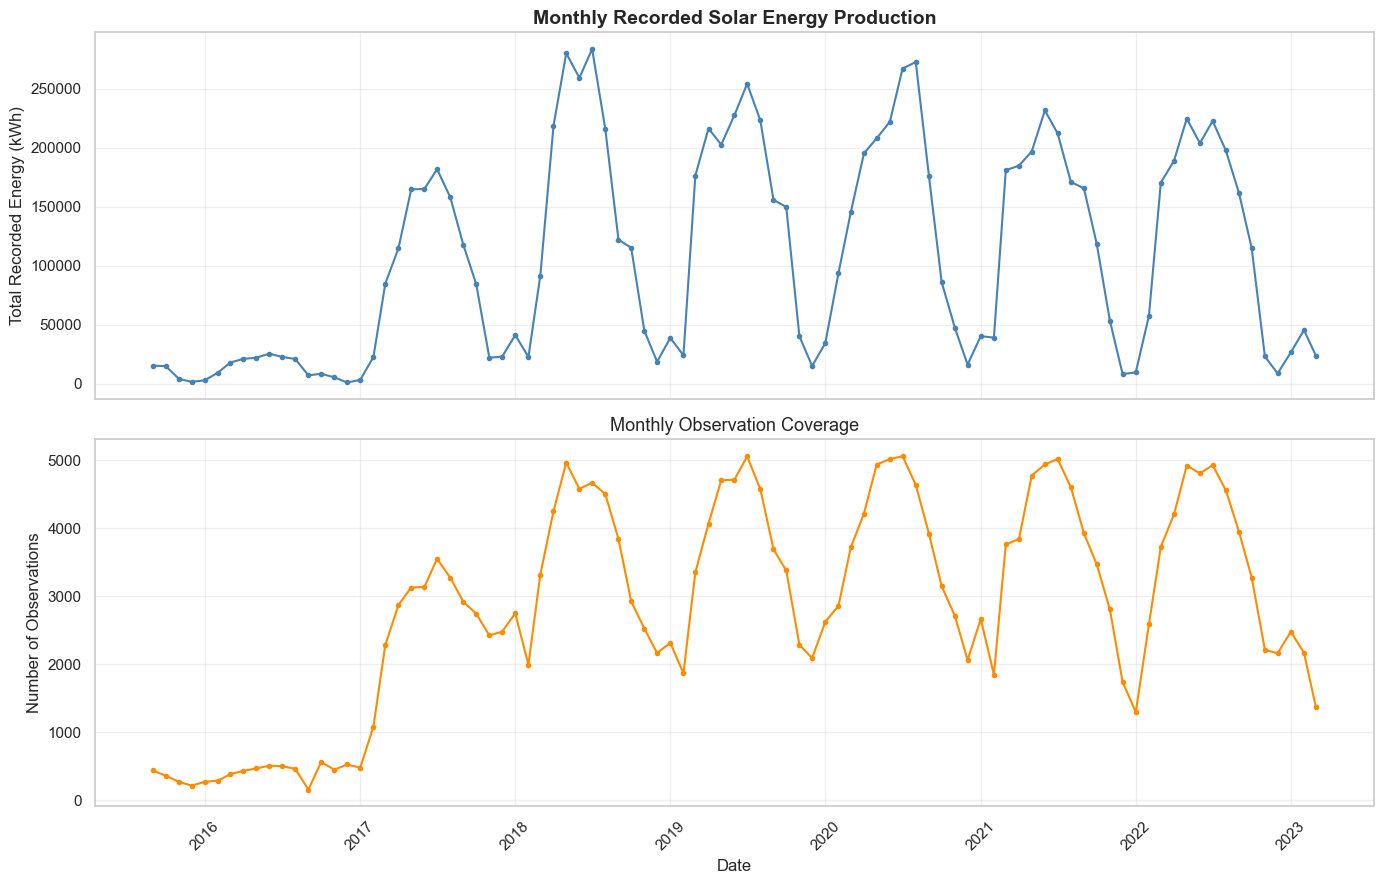

In [17]:

# Monthly recorded energy and observation coverage

import matplotlib.pyplot as plt

fig, axes = plt.subplots(
    2, 1, figsize=(14, 9), sharex=True
)

# Monthly total recorded energy
axes[0].plot(
    monthly_production["month_date"],
    monthly_production["total_kWh"],
    color="steelblue",
    marker="o",
    markersize=3,
    linewidth=1.5
)

axes[0].set_title(
    "Monthly Recorded Solar Energy Production",
    fontsize=14,
    fontweight="bold"
)
axes[0].set_ylabel("Total Recorded Energy (kWh)")
axes[0].grid(True, alpha=0.3)

# Monthly observation count
axes[1].plot(
    monthly_production["month_date"],
    monthly_production["observations"],
    color="darkorange",
    marker="o",
    markersize=3,
    linewidth=1.5
)

axes[1].set_title(
    "Monthly Observation Coverage",
    fontsize=13
)
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Number of Observations")
axes[1].grid(True, alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,mean,median,count
Jan,13.30,2.36,14894
Feb,21.46,2.66,14715
Mar,40.66,7.76,21937
Apr,47.69,11.62,23903
May,46.54,12.23,27920
Jun,48.17,12.87,27718
Jul,50.16,13.45,28804
Aug,47.31,12.92,26631
Sep,40.31,11.10,22864
Oct,34.88,7.58,19879


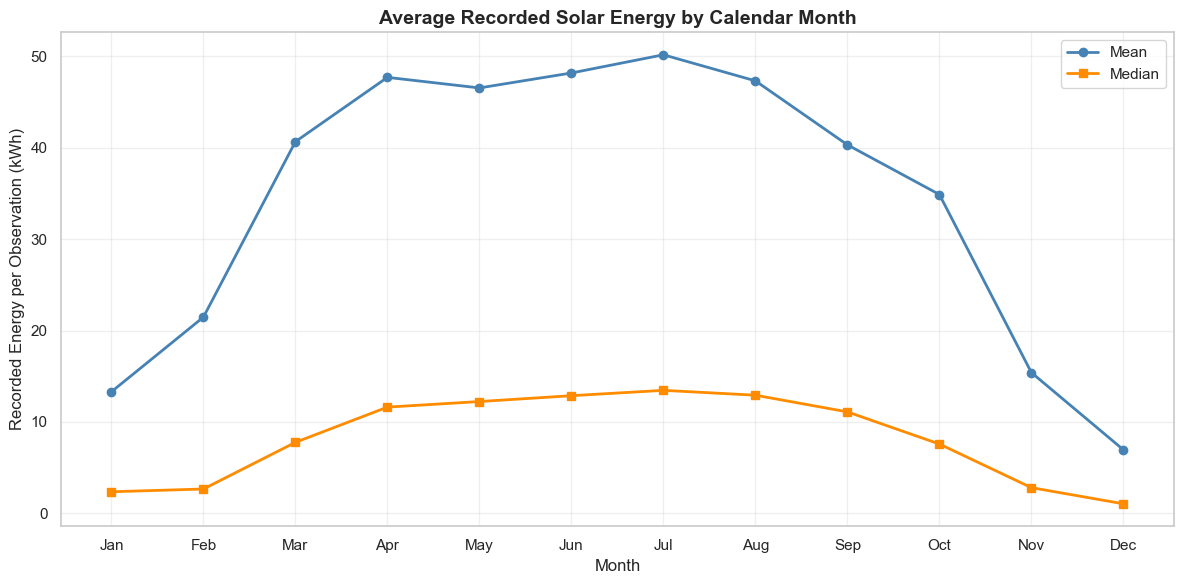

In [18]:

# Average recorded energy per observation by calendar month

monthly_pattern = (
    monthly_df.groupby(monthly_df["date"].dt.month)["kWh"]
    .agg(["mean", "median", "count"])
    .reindex(range(1, 13))
)

month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

monthly_pattern.index = month_names

display(monthly_pattern.round(2))

plt.figure(figsize=(12, 6))

plt.plot(
    month_names,
    monthly_pattern["mean"],
    marker="o",
    linewidth=2,
    color="steelblue",
    label="Mean"
)

plt.plot(
    month_names,
    monthly_pattern["median"],
    marker="s",
    linewidth=2,
    color="darkorange",
    label="Median"
)

plt.title(
    "Average Recorded Solar Energy by Calendar Month",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Month")
plt.ylabel("Recorded Energy per Observation (kWh)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 4.2.1 Interpretation of Monthly and Seasonal Solar Energy Production Patterns

The monthly analysis reveals a pronounced seasonal pattern in recorded solar energy production across the photovoltaic installations.

Both mean and median energy production generally increase from winter toward summer, reaching their highest values in July before declining toward December. July records the highest mean production of approximately **50.16 kWh per observation** and a median of **13.45 kWh**, while December records the lowest mean of **6.95 kWh** and a median of **1.04 kWh**.

This pattern is consistent with seasonal variations in solar energy availability, including changes in daylight duration and solar irradiance.

The mean consistently exceeds the median throughout the year, indicating a positively skewed distribution of recorded production values. This may reflect differences in installation capacities, operational characteristics, and the presence of relatively high production observations.

The monthly time-series analysis also demonstrates that total recorded energy closely follows observation coverage. Consequently, variations in monthly energy totals should not be interpreted solely as changes in physical solar generation, since differences in data availability can substantially influence aggregate production.

Overall, these findings demonstrate the importance of considering both seasonal patterns and observation coverage when interpreting photovoltaic energy production data. The results provide a foundation for further analysis of installation-specific performance and longer-term production trends.

## 4.3 Installation-Specific Solar Energy Production Analysis

### 4.3.1 Installation-Level Production Summary

This section examines variations in recorded solar energy
production across individual photovoltaic installations.
The analysis considers total production, average production,
median production, and observation coverage.

In [19]:
# Summarize solar energy production by installation

installation_summary = (
    df_clean.groupby(["id", "name"])
    .agg(
        observations=("kWh", "count"),
        total_kWh=("kWh", "sum"),
        mean_kWh=("kWh", "mean"),
        median_kWh=("kWh", "median"),
        max_kWh=("kWh", "max")
    )
    .reset_index()
)

# Sort installations by total recorded energy
installation_summary = installation_summary.sort_values(
    by="total_kWh",
    ascending=False
)

# Display results
print("Number of installations:", len(installation_summary))

display(installation_summary.round(2))

Number of installations: 11


,id,name,observations,total_kWh,mean_kWh,median_kWh,max_kWh
9,577650,Bearspaw Water Treatment Plant,24869,3082637.60,123.96,61.66,514.46
3,319086,Whitehorn Multi-Service Centre,27716,2558802.50,92.32,51.82,369.06
6,355827,Glenmore Water Treatment Plant,25920,1551177.72,59.84,32.76,239.97
0,164440,Southland Leisure Centre,31590,1147493.63,36.32,20.82,123.62
4,331901,City of Calgary North Corporate Warehouse,27092,768964.64,28.38,16.63,102.86
1,308057,Hillhurst Sunnyside Community Association,23467,186441.26,7.94,5.07,29.00
8,570079,Manchester Building M,22533,183243.24,8.13,4.50,34.12
7,551172,CFD Firehall #7,22659,170080.89,7.51,4.25,29.21
2,314106,Calgary Fire Hall Headquarters,25637,110211.61,4.30,2.48,16.60
5,332785,Richmond - Knob Hill Community Hall,26623,75130.28,2.82,1.90,9.28


### 4.3.2 Comparison of Total and Average Energy Production

The following visualizations compare total recorded energy
and mean energy per observation across photovoltaic installations.

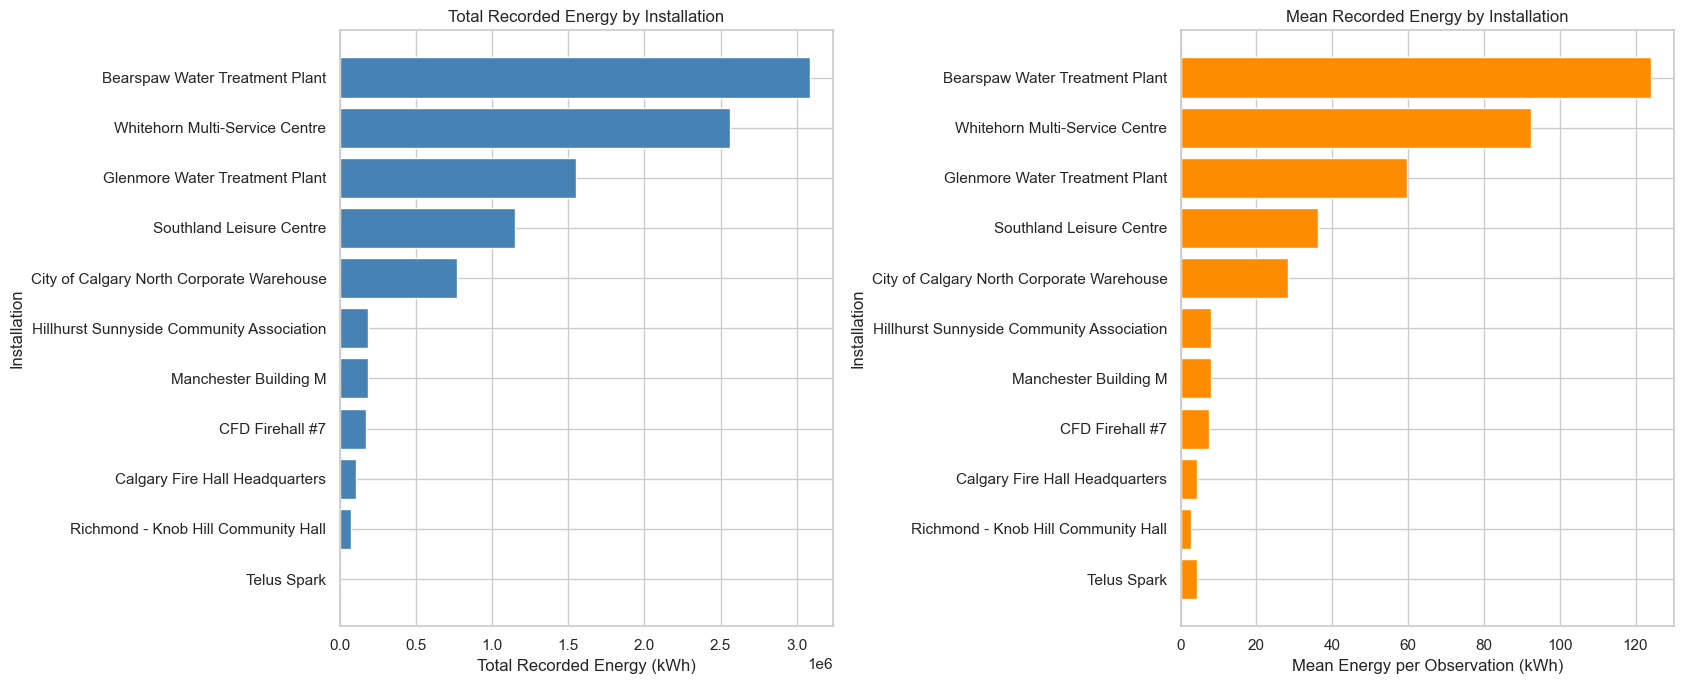

In [20]:

import matplotlib.pyplot as plt

# Sort installations by total recorded energy
plot_data = installation_summary.sort_values(
    "total_kWh", ascending=True
)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

# Chart 1: Total recorded energy
axes[0].barh(
    plot_data["name"],
    plot_data["total_kWh"],
    color="steelblue"
)
axes[0].set_title("Total Recorded Energy by Installation")
axes[0].set_xlabel("Total Recorded Energy (kWh)")
axes[0].set_ylabel("Installation")

# Chart 2: Mean recorded energy
axes[1].barh(
    plot_data["name"],
    plot_data["mean_kWh"],
    color="darkorange"
)
axes[1].set_title("Mean Recorded Energy by Installation")
axes[1].set_xlabel("Mean Energy per Observation (kWh)")
axes[1].set_ylabel("Installation")

plt.tight_layout()
plt.show()



**Interpretation**

The installation-level comparison reveals substantial differences
in recorded solar energy production across the 11 photovoltaic
installations.

Bearspaw Water Treatment Plant records the highest total and
mean energy production, followed by Whitehorn Multi-Service
Centre and Glenmore Water Treatment Plant.

The similar rankings of total and mean production suggest
that differences in average recorded energy contribute
substantially to the variation in cumulative production.

However, total production is also influenced by the number
of available observations. Telus Spark, for example, has
considerably fewer observations than the other installations.

Consequently, these comparisons describe recorded energy
production rather than installation efficiency. Differences
in installed capacity, observation coverage, and operating
conditions must be considered before drawing conclusions
about relative system performance.


### 4.3.3 Observation Coverage by Installation

This analysis examines the distribution of recorded observations
across photovoltaic installations to identify differences in
data availability that may influence production comparisons.

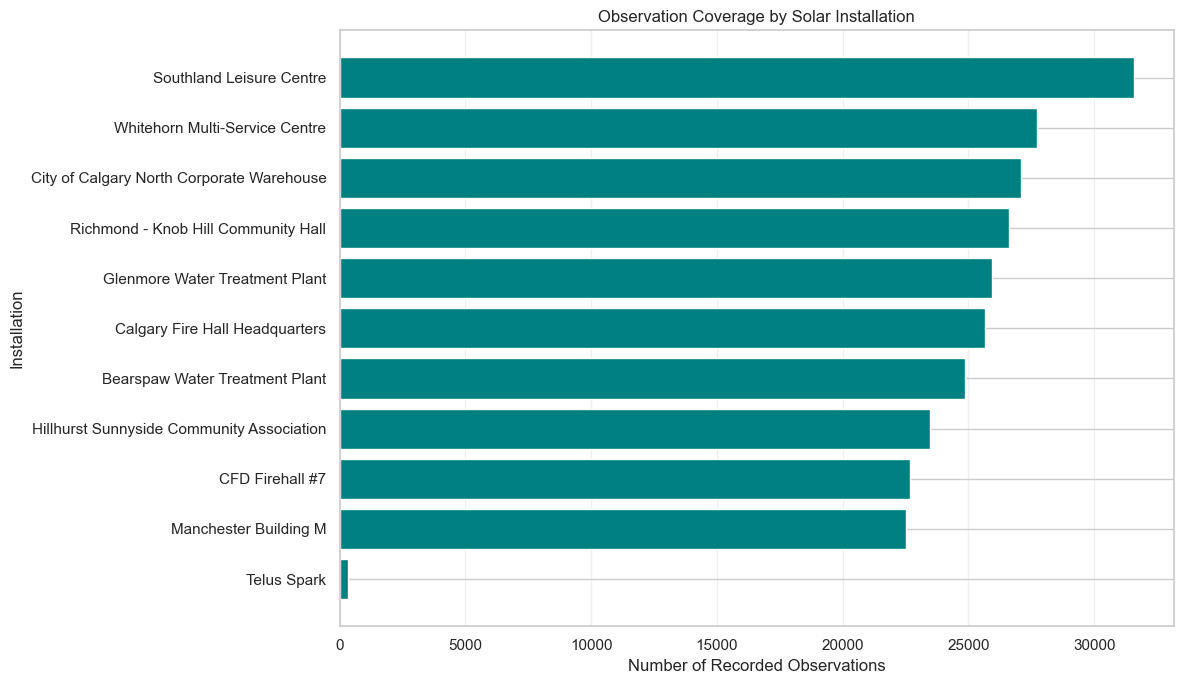

Observation coverage summary:


,name,observations
0,Southland Leisure Centre,31590
3,Whitehorn Multi-Service Centre,27716
4,City of Calgary North Corporate Warehouse,27092
5,Richmond - Knob Hill Community Hall,26623
6,Glenmore Water Treatment Plant,25920
2,Calgary Fire Hall Headquarters,25637
9,Bearspaw Water Treatment Plant,24869
1,Hillhurst Sunnyside Community Association,23467
7,CFD Firehall #7,22659
8,Manchester Building M,22533


In [21]:

# Examine observation coverage across installations

coverage = installation_summary.sort_values(
    "observations", ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    coverage["name"],
    coverage["observations"],
    color="teal"
)

plt.title("Observation Coverage by Solar Installation")
plt.xlabel("Number of Recorded Observations")
plt.ylabel("Installation")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# Display numerical summary
print("Observation coverage summary:")
display(
    installation_summary[
        ["name", "observations"]
    ].sort_values("observations", ascending=False)
)



**Interpretation**

The observation coverage analysis reveals differences in the
number of recorded measurements across the 11 photovoltaic
installations.

Southland Leisure Centre has the highest number of recorded
observations (31,590), while Manchester Building M has the
lowest count (22,533) among the 10 installations with
substantial observation coverage.

Telus Spark is a notable exception, contributing only 317
observations.

These differences are important because installations with
more recorded observations may accumulate greater total
energy values simply because they have more measurements.

Consequently, cumulative energy production should not be
used alone to compare installation performance.

Mean energy per observation provides an additional basis
for comparison, although differences in system capacity,
measurement frequency, and operating conditions must also
be considered.

The limited observations for Telus Spark suggest that its
results should be interpreted cautiously in subsequent
analyses.



### 4.3.4 Installation-Level Production Variability

This section examines the variability of recorded solar energy
production across photovoltaic installations using the standard
deviation and coefficient of variation (CV).

The coefficient of variation expresses standard deviation
relative to the mean, allowing differences in variability
to be compared across installations with different average
production levels.


Installation-level production variability:


,id,name,observations,mean_kWh,std_kWh,cv_percent
9,577650,Bearspaw Water Treatment Plant,24869,123.96,138.93,112.08
6,355827,Glenmore Water Treatment Plant,25920,59.84,64.48,107.74
8,570079,Manchester Building M,22533,8.13,8.74,107.41
3,319086,Whitehorn Multi-Service Centre,27716,92.32,96.60,104.63
0,164440,Southland Leisure Centre,31590,36.32,37.76,103.95
7,551172,CFD Firehall #7,22659,7.51,7.78,103.68
2,314106,Calgary Fire Hall Headquarters,25637,4.30,4.45,103.49
4,331901,City of Calgary North Corporate Warehouse,27092,28.38,29.07,102.41
10,594148,Telus Spark,317,4.21,4.22,100.28
1,308057,Hillhurst Sunnyside Community Association,23467,7.94,7.80,98.21


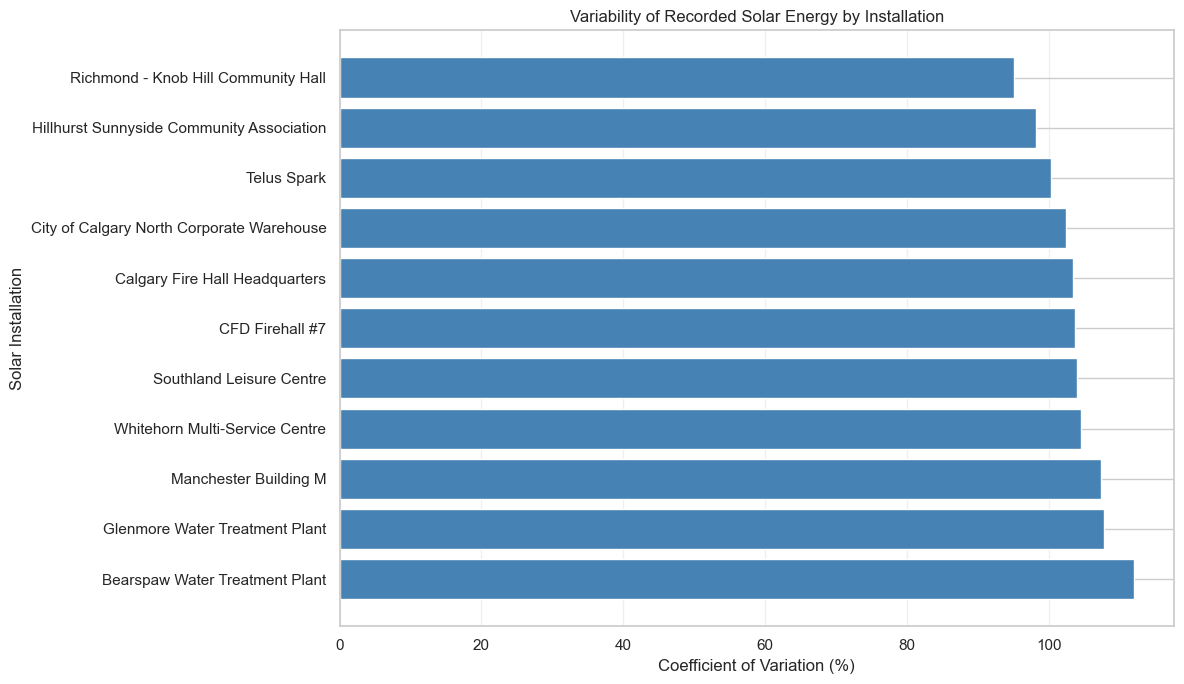

In [22]:

# Calculate installation-level production variability

installation_variability = (
    df_clean.groupby(["id", "name"])["kWh"]
    .agg(
        observations="count",
        mean_kWh="mean",
        std_kWh="std"
    )
    .reset_index()
)

# Calculate coefficient of variation (%)
installation_variability["cv_percent"] = (
    installation_variability["std_kWh"]
    / installation_variability["mean_kWh"]
) * 100

# Sort by coefficient of variation
installation_variability = (
    installation_variability.sort_values(
        "cv_percent", ascending=False
    )
)

print("Installation-level production variability:")
display(installation_variability.round(2))

# Visualize coefficient of variation
plt.figure(figsize=(12, 7))

plt.barh(
    installation_variability["name"],
    installation_variability["cv_percent"],
    color="steelblue"
)

plt.title(
    "Variability of Recorded Solar Energy by Installation"
)
plt.xlabel("Coefficient of Variation (%)")
plt.ylabel("Solar Installation")
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()



**Interpretation**

The installation-level variability analysis reveals substantial
variation in recorded photovoltaic energy production across
all 11 installations.

The coefficient of variation ranges from 95.12% to 112.08%,
indicating that the standard deviation is approximately equal
to or greater than the mean recorded production for most
installations.

Bearspaw Water Treatment Plant exhibits the highest relative
variability (112.08%), followed by Glenmore Water Treatment
Plant (107.74%) and Manchester Building M (107.41%).

Richmond - Knob Hill Community Hall exhibits the lowest
coefficient of variation (95.12%).

These findings are consistent with the highly variable nature
of solar energy production, which depends on daylight
availability, seasonal changes, weather conditions, and
installation characteristics.

Importantly, the analysis includes observations from different
hours and seasons. Consequently, high variability should not
be interpreted as evidence of poor system reliability or
inefficiency.

Further analysis that accounts for temporal patterns would
be required to evaluate operational consistency.



## 4.4 Year-over-Year Solar Energy Production Analysis

This section investigates annual trends in recorded photovoltaic
energy production across the study period.

The analysis examines annual total production, average and
median production per observation, and observation coverage.

Because the number of available observations varies across
years, changes in total recorded energy are interpreted
alongside changes in data availability.


In [23]:

# Section 4.4.1 - Annual Solar Energy Production Summary

# Aggregate solar energy production by year
annual_production = (
    df_clean.groupby("year")["kWh"]
    .agg(
        total_kWh="sum",
        mean_kWh="mean",
        median_kWh="median",
        observations="count"
    )
    .reset_index()
    .sort_values("year")
)

# Display the annual production summary
print("Annual Solar Energy Production Summary:")
display(annual_production.round(2))

# Check the number of years covered
print(
    "\nNumber of years:",
    annual_production["year"].nunique()
)

# Check the total number of observations
print(
    "Total observations:",
    annual_production["observations"].sum()
)


Annual Solar Energy Production Summary:


,year,total_kWh,mean_kWh,median_kWh,observations
0,2015,36569.78,28.30,15.37,1292
1,2016,166261.72,33.05,15.73,5030
2,2017,1143066.05,37.60,7.76,30397
3,2018,1714572.43,40.33,7.28,42516
4,2019,1725008.98,40.94,8.03,42132
5,2020,1765072.18,39.27,8.29,44943
6,2021,1603814.99,36.93,8.81,43430
7,2022,1584847.50,37.16,8.31,42655
8,2023,96304.30,15.98,2.93,6028



Number of years: 9
Total observations: 258423



**Interpretation**

The annual solar energy production summary covers nine calendar
years (2015–2023), comprising 258,423 recorded observations.

Total recorded energy production increased substantially between
2015 and 2020, reaching its highest annual value of approximately
1.77 million kWh in 2020.

However, the number of observations also increased significantly
over this period. The highest annual observation count (44,943)
was recorded in 2020.

Mean energy production per observation reached its highest value
of 40.94 kWh in 2019, compared with 39.27 kWh in 2020.

Total recorded production subsequently decreased in 2021 and
2022, while mean production remained relatively close to
the levels observed during 2017–2020.

The dataset includes partial coverage of 2015 and 2023.
Consequently, the lower totals for these years should not
be interpreted as evidence of reduced photovoltaic performance.

Overall, annual production trends must be considered alongside
observation coverage and changes in the installations represented
in the dataset.



### 4.4.2 Visualization of Annual Solar Energy Production Trends

This section visualizes annual total recorded solar energy,
mean energy production per observation, and observation coverage.

The three indicators are examined together to distinguish
changes in recorded energy production from differences in
the availability of measurements.


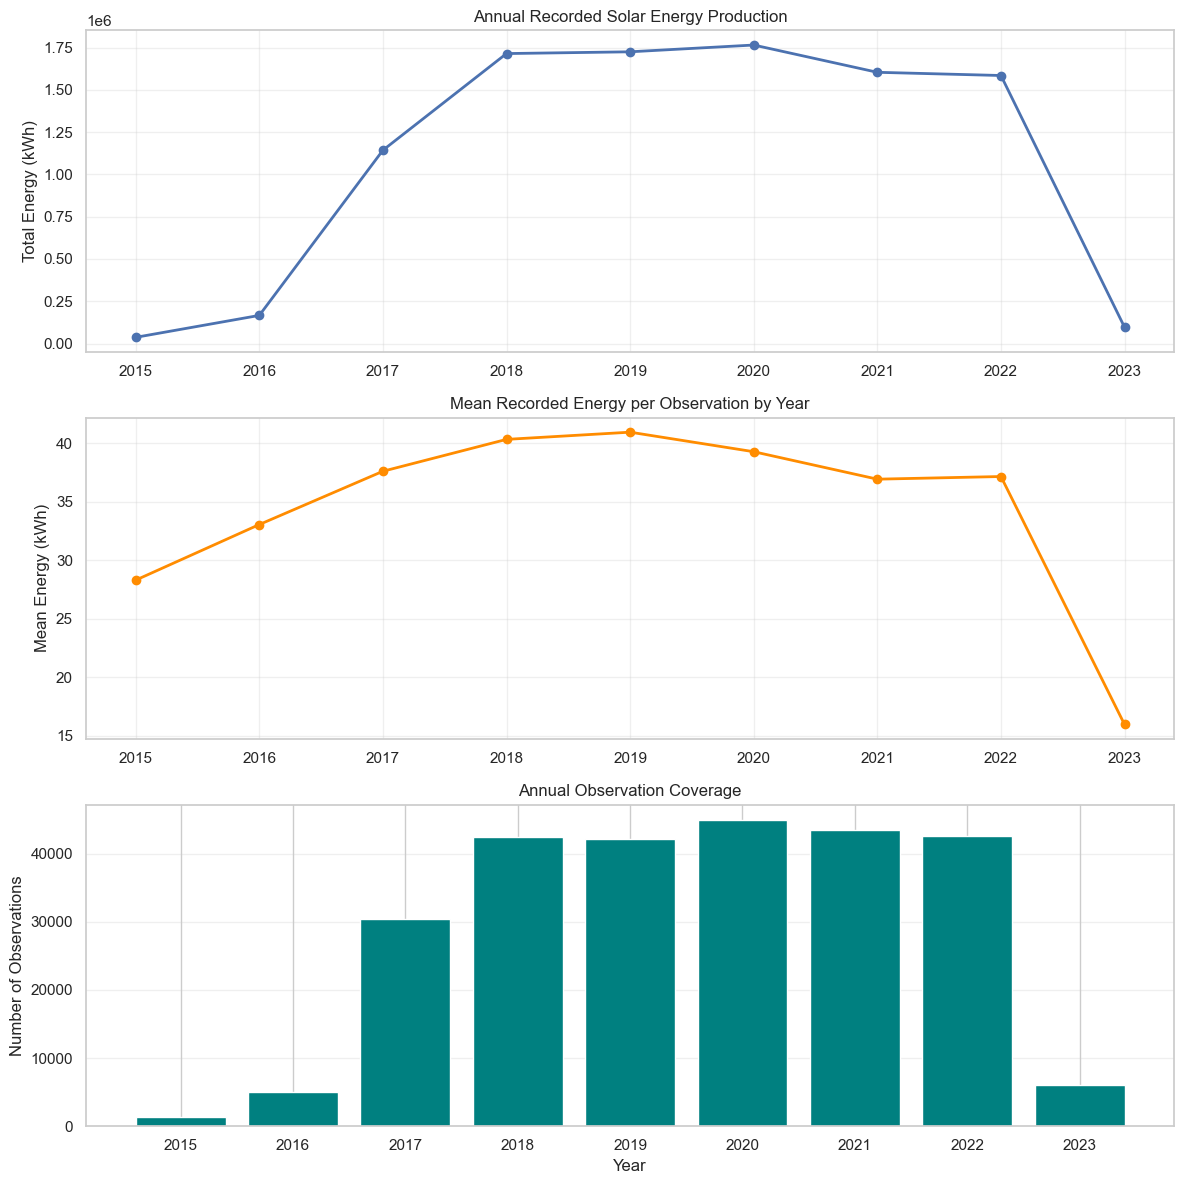

In [24]:

# Visualize annual solar energy production trends

fig, axes = plt.subplots(3, 1, figsize=(12, 12))

# Chart 1: Total annual production
axes[0].plot(
    annual_production["year"],
    annual_production["total_kWh"],
    marker="o",
    linewidth=2
)
axes[0].set_title("Annual Recorded Solar Energy Production")
axes[0].set_ylabel("Total Energy (kWh)")
axes[0].grid(alpha=0.3)

# Chart 2: Mean energy per observation
axes[1].plot(
    annual_production["year"],
    annual_production["mean_kWh"],
    marker="o",
    color="darkorange",
    linewidth=2
)
axes[1].set_title("Mean Recorded Energy per Observation by Year")
axes[1].set_ylabel("Mean Energy (kWh)")
axes[1].grid(alpha=0.3)

# Chart 3: Annual observation coverage
axes[2].bar(
    annual_production["year"],
    annual_production["observations"],
    color="teal"
)
axes[2].set_title("Annual Observation Coverage")
axes[2].set_xlabel("Year")
axes[2].set_ylabel("Number of Observations")
axes[2].grid(axis="y", alpha=0.3)

# Display all years
for ax in axes:
    ax.set_xticks(annual_production["year"])

plt.tight_layout()
plt.show()



**Interpretation of Annual Production Trends**

The annual visualizations reveal substantial changes in recorded
solar energy production and observation coverage between 2015
and 2023.

Total recorded energy production increased significantly from
2015 to 2018, reaching approximately 1.71 million kWh in 2018.
Production remained relatively stable through 2020, when the
highest annual total of approximately 1.77 million kWh was
recorded.

Mean recorded energy per observation followed a similar upward
trend during the earlier years, reaching a maximum of 40.94 kWh
in 2019. Between 2020 and 2022, mean production remained
relatively stable, ranging from approximately 36.93 to
39.27 kWh.

Observation coverage increased substantially between 2015
and 2018, indicating that part of the growth in recorded
production may be associated with improved data availability
or changes in the installations represented.

Annual observation counts were more consistent between 2018
and 2022, making this period more suitable for comparisons,
although differences in installation composition and
measurement frequency must still be considered.

The sharp decreases observed in 2023 should be interpreted
cautiously because the dataset contains only partial-year
observations.

Overall, the findings demonstrate that recorded solar energy
production is influenced by both energy generation patterns
and observation coverage. Consequently, annual totals alone
are insufficient for assessing photovoltaic performance.



### 4.4.3 Year-over-Year Changes in Solar Energy Production

This section evaluates year-over-year percentage changes in
total recorded solar energy production, mean energy per
observation, and observation coverage.

The objective is to quantify annual variations and examine
whether changes in recorded energy production coincide with
changes in the number of available observations.


In [25]:

# Calculate year-over-year changes in solar energy production

annual_changes = annual_production.copy()

# Calculate annual percentage changes
annual_changes["total_change_pct"] = (
    annual_changes["total_kWh"].pct_change() * 100
)

annual_changes["mean_change_pct"] = (
    annual_changes["mean_kWh"].pct_change() * 100
)

annual_changes["observations_change_pct"] = (
    annual_changes["observations"].pct_change() * 100
)

# Display annual percentage changes
columns = [
    "year",
    "total_change_pct",
    "mean_change_pct",
    "observations_change_pct"
]

print("Year-over-Year Solar Energy Production Changes:")

display(annual_changes[columns].round(2))


Year-over-Year Solar Energy Production Changes:


,year,total_change_pct,mean_change_pct,observations_change_pct
0,2015,NaN,NaN,NaN
1,2016,354.64,16.78,289.32
2,2017,587.51,13.77,504.31
3,2018,50.00,7.24,39.87
4,2019,0.61,1.53,-0.90
5,2020,2.32,-4.08,6.67
6,2021,-9.14,-5.97,-3.37
7,2022,-1.18,0.61,-1.78
8,2023,-93.92,-57.00,-85.87



**Interpretation of Year-over-Year Production Changes**

The year-over-year analysis reveals substantial variations in
recorded solar energy production between 2016 and 2023.

Between 2016 and 2018, total recorded energy increased
considerably, with annual growth rates of 354.64%, 587.51%,
and 50.00%, respectively. These increases coincided with
significant improvements in observation coverage, suggesting
that data availability contributed to the recorded growth.

From 2019 to 2022, annual changes became comparatively
moderate. In 2020, total recorded production increased by
2.32%, despite a 4.08% decrease in mean energy per
observation. This difference coincided with a 6.67%
increase in observation coverage.

In 2021, total recorded production decreased by 9.14%,
accompanied by decreases in both mean energy per
observation (-5.97%) and observation coverage (-3.37%).

In 2022, total recorded production decreased slightly
by 1.18%, while mean energy per observation increased
by 0.61%.

The substantial declines observed in 2023 should not
be interpreted as evidence of deteriorating photovoltaic
performance because the dataset contains only partial-year
observations.

Overall, the results demonstrate that annual changes in
recorded energy production reflect variations in both
energy generation per observation and observation coverage.
Consequently, changes in total recorded production should
not automatically be interpreted as changes in solar
installation efficiency.


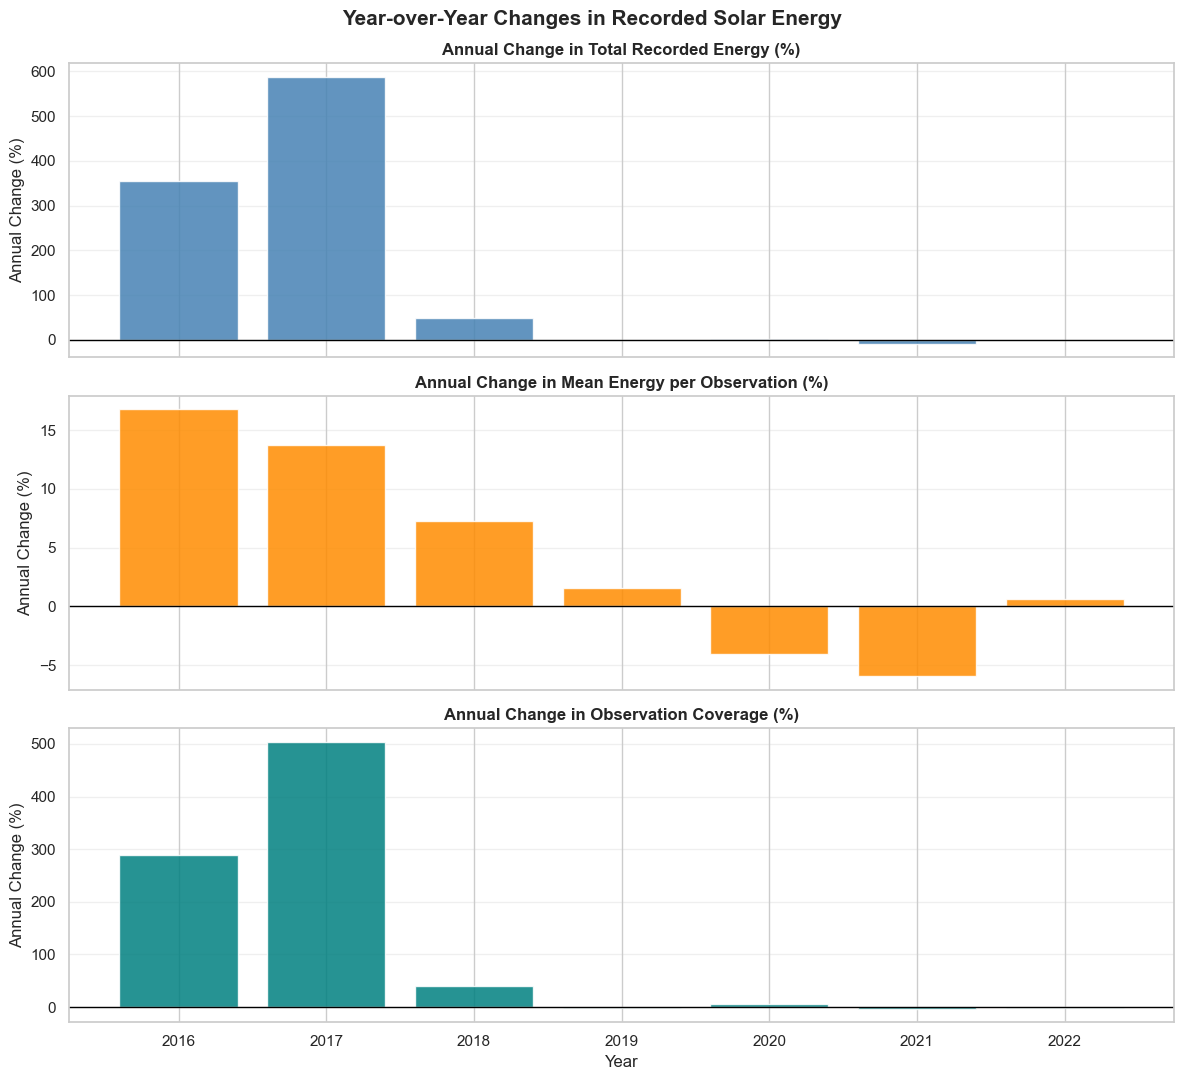

In [26]:

# Visualize year-over-year solar energy production changes

import matplotlib.pyplot as plt

# Exclude 2015 (no previous year) and 2023 (partial year)
plot_data = annual_changes[
    annual_changes["year"].between(2016, 2022)
].copy()

fig, axes = plt.subplots(
    3, 1, figsize=(12, 11), sharex=True
)

metrics = [
    ("total_change_pct",
     "Annual Change in Total Recorded Energy (%)",
     "steelblue"),
    ("mean_change_pct",
     "Annual Change in Mean Energy per Observation (%)",
     "darkorange"),
    ("observations_change_pct",
     "Annual Change in Observation Coverage (%)",
     "teal")
]

for ax, (column, title, color) in zip(axes, metrics):
    ax.bar(
        plot_data["year"],
        plot_data[column],
        color=color,
        alpha=0.85
    )

    ax.axhline(0, color="black", linewidth=1)
    ax.set_title(title, fontweight="bold")
    ax.set_ylabel("Annual Change (%)")
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

axes[-1].set_xlabel("Year")
axes[-1].set_xticks(plot_data["year"])

plt.suptitle(
    "Year-over-Year Changes in Recorded Solar Energy",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



**Interpretation of Year-over-Year Changes**

The year-over-year visualizations demonstrate a strong
relationship between changes in total recorded solar energy
production and changes in observation coverage.

The largest increases in total recorded production occurred
in 2016 and 2017, coinciding with substantial increases in
the number of observations. This suggests that expanded
data coverage contributed significantly to the recorded
growth.

From 2019 to 2022, annual changes were considerably smaller,
reflecting a period of more stable observation coverage.

Mean energy per observation increased during the earlier
years but declined in 2020 and 2021 before recovering
slightly in 2022.

These findings highlight the importance of distinguishing
between changes in recorded energy production and changes
in data availability.

Because total recorded energy is mathematically dependent
on both mean energy per observation and observation count,
annual production totals should not be interpreted as
direct measures of photovoltaic efficiency.

Overall, the analysis provides a foundation for further
investigation of installation-level performance and
temporal variations in solar energy production.
